In [39]:
# 1. Workspace inspection and repository skeleton validation
from pathlib import Path

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
required = [
    "backend",
    "ml/common",
    "ml/vision",
    "ml/text",
    "ml/tabular",
    "configs",
    "data/raw",
    "data/processed",
    "artifacts",
    "reports",
    "tests",
    "docs",
    "notebooks",
]
created = []
for relative in required:
    target = ROOT / relative
    if not target.exists():
        target.mkdir(parents=True, exist_ok=True)
        created.append(relative)
print(
    {
        "root": str(ROOT),
        "created_missing_directories": created,
        "mission_present": (ROOT / "Mission.md").is_file(),
    }
)

{'root': '/home/neptune/Documents/Personal-Projects/AI-Lead', 'created_missing_directories': [], 'mission_present': True}


In [40]:
# 2. Environment compatibility and dependency lock snapshot
import importlib.metadata as package_metadata
import json
import sys
from packaging.version import Version

requirements = {
    "fastapi": ("0.115", "1"),
    "scikit-learn": ("1.6", "2"),
    "pandas": ("2.2", "4"),
    "numpy": ("2", "3"),
}
versions = {
    name: package_metadata.version(name)
    for name in (
        "fastapi",
        "pydantic",
        "scikit-learn",
        "pandas",
        "numpy",
        "Pillow",
        "torch",
        "torchvision",
    )
    if any(
        distribution.metadata.get("Name", "").lower() == name.lower()
        for distribution in package_metadata.distributions()
    )
}
assert Version(sys.version.split()[0]) >= Version("3.11") and Version(
    sys.version.split()[0]
) < Version("3.14")
for name, (minimum, maximum) in requirements.items():
    if name in versions:
        assert Version(minimum) <= Version(versions[name]) < Version(maximum), (
            name,
            versions[name],
        )
all_packages = sorted(
    {
        distribution.metadata.get("Name", "unknown"): distribution.version
        for distribution in package_metadata.distributions()
    }.items()
)
report_dir = ROOT / "reports"
report_dir.mkdir(parents=True, exist_ok=True)
(report_dir / "environment-snapshot.json").write_text(
    json.dumps(
        {"python": sys.version.split()[0], "packages": dict(all_packages)}, indent=2
    )
    + "\n",
    encoding="utf-8",
)
print(
    {
        "python": sys.version.split()[0],
        "compatibility_packages": versions,
        "snapshot": "reports/environment-snapshot.json",
        "package_count": len(all_packages),
        "torchvision_requires_vision_extra": "torch" not in versions,
    }
)

{'python': '3.12.3', 'compatibility_packages': {'fastapi': '0.162.4', 'pydantic': '2.14.3', 'scikit-learn': '1.9.1', 'pandas': '3.1.1', 'numpy': '2.5.4', 'Pillow': '12.3.0'}, 'snapshot': 'reports/environment-snapshot.json', 'package_count': 71, 'torchvision_requires_vision_extra': True}


In [41]:
# 3. Global configuration, paths, and reproducibility seeds
import json
import random
import numpy as np

CONFIG = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
SEED = int(CONFIG["seed"])
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
except ImportError:
    torch = None
print(
    {
        "seed": SEED,
        "text_split": "grouped stratified",
        "bike_split": "chronological 70/15/15",
        "vision_classes": CONFIG["vision"]["classes"],
        "torch_available": torch is not None,
    }
)

{'seed': 42, 'text_split': 'grouped stratified', 'bike_split': 'chronological 70/15/15', 'vision_classes': ['keyboard', 'mouse', 'headphones'], 'torch_available': False}


In [42]:
# 4. Local data/artifact registry with checksums
from datetime import datetime, timezone
from ml.common.artifacts import ARTIFACTS, DATA, REPORTS, sha256_file
from ml.text.pipeline import SOURCE_INFO as SMS_SOURCE
from ml.tabular.pipeline import SOURCE_INFO as BIKE_SOURCE

REGISTRY = {
    "captured_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_sources": {"sms": SMS_SOURCE, "bike": BIKE_SOURCE},
    "datasets": {},
    "artifacts": {},
}
for source in (
    DATA / "raw/sms+spam+collection.zip",
    DATA / "raw/bike-sharing-dataset.zip",
    DATA / "raw/equipment/manifest.csv",
):
    if source.is_file():
        REGISTRY["datasets"][str(source.relative_to(ROOT))] = {
            "sha256": sha256_file(source),
            "bytes": source.stat().st_size,
        }
for artifact in ARTIFACTS.rglob("*") if ARTIFACTS.exists() else []:
    if artifact.is_file() and artifact.suffix in {".joblib", ".pt", ".json"}:
        REGISTRY["artifacts"][str(artifact.relative_to(ROOT))] = {
            "sha256": sha256_file(artifact),
            "bytes": artifact.stat().st_size,
        }
REPORTS.mkdir(parents=True, exist_ok=True)
(REPORTS / "local-registry.json").write_text(
    json.dumps(REGISTRY, indent=2) + "\n", encoding="utf-8"
)
print(
    {
        "datasets": len(REGISTRY["datasets"]),
        "artifacts": len(REGISTRY["artifacts"]),
        "registry": "reports/local-registry.json",
    }
)

{'datasets': 2, 'artifacts': 8, 'registry': 'reports/local-registry.json'}


In [43]:
# 5. SMS download, attribution capture, and source-format parsing
from ml.text import pipeline as text_pipeline

RUN_DATA_PREP = False  # Set True to download the official UCI archive explicitly.
print(text_pipeline.SOURCE_INFO)
sms_archive = DATA / "raw/sms+spam+collection.zip"
if RUN_DATA_PREP:
    print("Prepared rows:", text_pipeline.prepare_data())
elif sms_archive.is_file():
    parsed_sms = text_pipeline.parse_source(sms_archive)
    assert set(parsed_sms["label"].unique()) <= {"ham", "spam"}
    assert parsed_sms["text"].str.strip().ne("").all()
    print(
        {
            "parsed_rows": len(parsed_sms),
            "labels": parsed_sms["label"].value_counts().to_dict(),
            "raw_messages_printed": False,
        }
    )
else:
    print(
        "Awaiting official source archive; run ml.text.cli prepare or set RUN_DATA_PREP=True."
    )

{'name': 'SMS Spam Collection', 'repository': 'UCI Machine Learning Repository', 'dataset_id': 228, 'url': 'https://archive.ics.uci.edu/dataset/228/sms+spam+collection', 'license': 'CC BY 4.0', 'attribution': 'Almeida, T. A., Gómez Hidalgo, J. M., and Yamakami, A. (2011). Contributions to the Study of SMS Spam Filtering: New Collection and Results.'}
{'parsed_rows': 5572, 'labels': {'ham': 4825, 'spam': 747}, 'raw_messages_printed': False}


In [44]:
# 6. SMS fixed split manifest, stratified grouping, and duplicate guards
sms_processed = DATA / "processed/text"
sms_manifest_path = sms_processed / "manifest.json"
if sms_manifest_path.is_file():
    sms_manifest = json.loads(sms_manifest_path.read_text(encoding="utf-8"))
    train_sms = __import__("pandas").read_csv(
        sms_processed / "train.csv", usecols=["group_id", "label"]
    )
    validation_sms = __import__("pandas").read_csv(
        sms_processed / "validation.csv", usecols=["group_id", "label"]
    )
    assert not (set(train_sms.group_id) & set(validation_sms.group_id))
    assert sms_manifest["split_method"].startswith("StratifiedGroupKFold")
    print(
        {
            "train_rows": len(train_sms),
            "validation_rows": len(validation_sms),
            "train_validation_duplicate_overlap": 0,
            "private_test_rows_opened": False,
            "manifest_sha256": sha256_file(sms_manifest_path),
        }
    )
else:
    print("SMS split manifest missing; run python -m ml.text.cli prepare.")

{'train_rows': 4457, 'validation_rows': 557, 'train_validation_duplicate_overlap': 0, 'private_test_rows_opened': False, 'manifest_sha256': '01b4a3b461a4dcebbcfd7d4caa975ee19b4d3b18fa319d53a7a4d1b84bfadc51'}


In [45]:
# 7. SMS starter vs AI Lead training and validation evaluation
from ml.text import pipeline as text_pipeline

RUN_EXPERIMENTS = (
    False  # Training is explicit; this cell never evaluates the private test split.
)
for model_id in ("starter", "ai-lead"):
    report_path = REPORTS / "validation" / f"text-{model_id}.json"
    if RUN_EXPERIMENTS:
        text_pipeline.train(model_id)
        report = text_pipeline.evaluate(model_id, "validation")
        print(
            model_id,
            report["metrics"],
            "majority-reference",
            report["reference"]["metrics"],
        )
    elif report_path.is_file():
        report = json.loads(report_path.read_text(encoding="utf-8"))
        print(
            model_id,
            report["split"],
            report["metrics"]["macro_f1"],
            "majority-reference",
            report.get("reference", {}).get("metrics", {}).get("macro_f1"),
        )
    else:
        print(model_id, "not evaluated; set RUN_EXPERIMENTS=True after prepare.")
print("Final test: organiser CLI only, run at most once with --organiser.")

starter validation 0.8578211149683479 majority-reference 0.46442307692307694
ai-lead validation 0.9497473836160231 majority-reference 0.46442307692307694
Final test: organiser CLI only, run at most once with --organiser.


In [46]:
# 8. Bike source download, field validation, and physical-unit mapping
from ml.tabular import pipeline as bike_pipeline

print(bike_pipeline.SOURCE_INFO)
bike_archive = DATA / "raw/bike-sharing-dataset.zip"
if bike_archive.is_file():
    bike_frame = bike_pipeline.parse_source(bike_archive)
    assert {"cnt", "temp", "atemp", "hum", "windspeed"}.issubset(bike_frame.columns)
    assert not ({"casual", "registered", "instant"} & set(bike_pipeline.FEATURES))
    print(
        {
            "hourly_rows": len(bike_frame),
            "target": "cnt",
            "physical_input_encoding": {
                "temperature_c": "temp_c / 41",
                "feels_like_c": "atemp_c / 50",
                "humidity_percent": "percent / 100",
                "wind_speed_kmh": "km/h / 67",
            },
            "private_test_rows_printed": False,
        }
    )
else:
    print(
        "Awaiting official source archive; run python -m ml.tabular.cli prepare or set RUN_DATA_PREP=True."
    )
if RUN_DATA_PREP:
    print("Prepared rows:", bike_pipeline.prepare_data())

{'name': 'Bike Sharing Dataset', 'repository': 'UCI Machine Learning Repository', 'dataset_id': 275, 'url': 'https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset', 'license': 'CC BY 4.0', 'attribution': 'Fanaee-T, H. (2013). Bike Sharing Dataset. UCI Machine Learning Repository.', 'target': 'cnt (total hourly rentals)'}
{'hourly_rows': 17379, 'target': 'cnt', 'physical_input_encoding': {'temperature_c': 'temp_c / 41', 'feels_like_c': 'atemp_c / 50', 'humidity_percent': 'percent / 100', 'wind_speed_kmh': 'km/h / 67'}, 'private_test_rows_printed': False}


In [47]:
# 9. Bike chronological splits and target-leakage exclusion checks
bike_processed = DATA / "processed/tabular"
bike_manifest_path = bike_processed / "manifest.json"
if bike_manifest_path.is_file():
    bike_manifest = json.loads(bike_manifest_path.read_text(encoding="utf-8"))
    train_bike = __import__("pandas").read_csv(
        bike_processed / "train.csv", parse_dates=["dteday"]
    )
    validation_bike = __import__("pandas").read_csv(
        bike_processed / "validation.csv", parse_dates=["dteday"]
    )
    last_train = tuple(train_bike.iloc[-1][["dteday", "hr"]])
    first_validation = tuple(validation_bike.iloc[0][["dteday", "hr"]])
    assert last_train < first_validation
    assert not (
        {"casual", "registered", "instant", "cnt"} & set(bike_pipeline.FEATURES)
    )
    assert bike_manifest["split_method"].startswith("chronological")
    print(
        {
            "train_rows": len(train_bike),
            "validation_rows": len(validation_bike),
            "feature_count": len(bike_pipeline.FEATURES),
            "excluded": sorted(bike_pipeline.EXCLUDED),
            "private_test_rows_opened": False,
        }
    )
else:
    print("Bike split manifest missing; run python -m ml.tabular.cli prepare.")

{'train_rows': 12165, 'validation_rows': 2607, 'feature_count': 12, 'excluded': ['casual', 'cnt', 'dteday', 'instant', 'registered'], 'private_test_rows_opened': False}


starter MAE 125.93331127795801 RMSE 167.1511292576736 rentals/hour


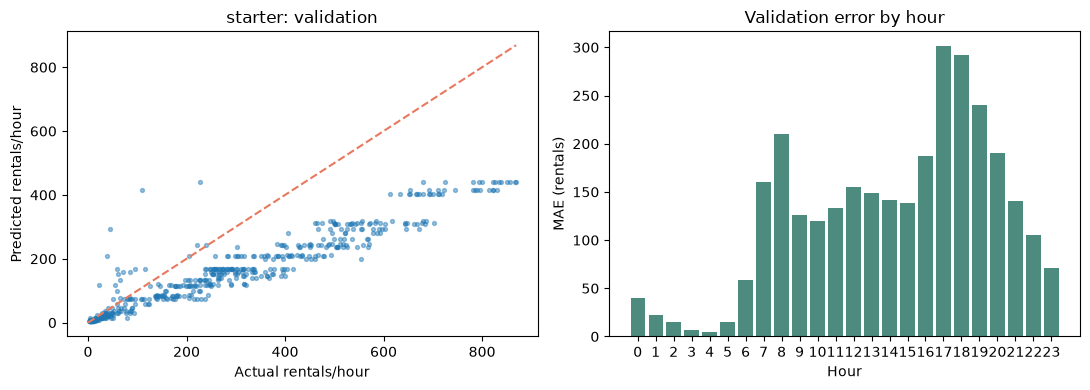

ai-lead MAE 45.28093483432363 RMSE 66.75134568605031 rentals/hour


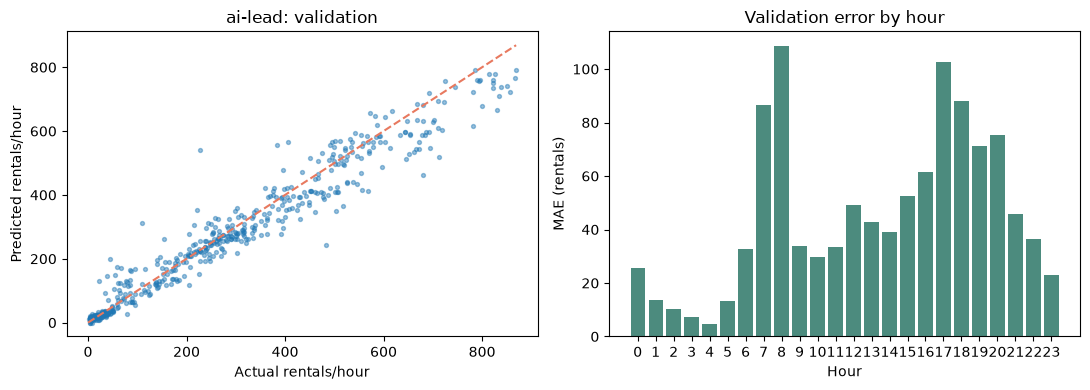

In [48]:
# 10. Bike starter vs AI Lead training, validation metrics, and error plots
from ml.tabular import pipeline as bike_pipeline

RUN_EXPERIMENTS = (
    False  # Set True to train both baselines and refresh validation reports.
)
if RUN_EXPERIMENTS:
    for model_id in ("starter", "ai-lead"):
        bike_pipeline.train(model_id)
        print(bike_pipeline.evaluate(model_id, "validation"))
for model_id in ("starter", "ai-lead"):
    report_path = REPORTS / "validation" / f"tabular-{model_id}.json"
    if report_path.is_file():
        report = json.loads(report_path.read_text(encoding="utf-8"))
        print(
            model_id,
            "MAE",
            report["metrics"]["mae"],
            "RMSE",
            report["metrics"]["rmse"],
            "rentals/hour",
        )
        sample = report["metrics"].get("predicted_actual_sample", [])
        if sample:
            import matplotlib.pyplot as plt

            actual = [point["actual"] for point in sample]
            predicted = [point["predicted"] for point in sample]
            figure, axes = plt.subplots(1, 2, figsize=(11, 4))
            axes[0].scatter(actual, predicted, s=8, alpha=0.45)
            axes[0].plot(
                [0, max(actual)], [0, max(actual)], color="#e8795f", linestyle="--"
            )
            axes[0].set(
                xlabel="Actual rentals/hour",
                ylabel="Predicted rentals/hour",
                title=f"{model_id}: validation",
            )
            errors = report["metrics"]["errors_by_hour"]
            axes[1].bar(list(errors), list(errors.values()), color="#4c8b7e")
            axes[1].set(
                xlabel="Hour", ylabel="MAE (rentals)", title="Validation error by hour"
            )
            figure.tight_layout()
            plt.show()
    else:
        print(model_id, "not evaluated; prepare and train the model first.")

In [49]:
# 11. Vision manifest ingestion and readiness state
from ml.vision import pipeline as vision_pipeline

vision_root = DATA / "raw/equipment"
vision_source_manifest = vision_root / "manifest.csv"
vision_processed_manifest = DATA / "processed/vision/manifest.json"
if vision_source_manifest.is_file():
    import pandas as pd

    source_rows = pd.read_csv(vision_source_manifest)
    checked = vision_pipeline.validate_manifest(source_rows, vision_root)
    print(
        {
            "status": "dataset present; validate with prepare",
            "images": len(checked),
            "classes": sorted(checked.label.unique()),
            "required_metadata": vision_pipeline.MANIFEST_FIELDS,
        }
    )
else:
    print(
        {
            "status": "awaiting dataset",
            "required_classes": vision_pipeline.CLASSES,
            "next_command_after_collection": "python -m ml.vision.cli prepare",
            "model_not_trained": True,
        }
    )

{'status': 'awaiting dataset', 'required_classes': ['keyboard', 'mouse', 'headphones'], 'next_command_after_collection': 'python -m ml.vision.cli prepare', 'model_not_trained': True}


In [50]:
# 12. Vision object split integrity, duplicate detection, and overlap warnings
vision_splits_dir = DATA / "processed/vision"
if all(
    (vision_splits_dir / f"{name}.csv").is_file()
    for name in ("train", "validation", "test")
):
    import pandas as pd

    train_images = pd.read_csv(vision_splits_dir / "train.csv")
    validation_images = pd.read_csv(vision_splits_dir / "validation.csv")
    assert not (
        set(train_images.physical_object_id) & set(validation_images.physical_object_id)
    )
    train_hashes = {
        vision_pipeline.image_hash(vision_root / path)
        for path in train_images.image_path
    }
    validation_hashes = {
        vision_pipeline.image_hash(vision_root / path)
        for path in validation_images.image_path
    }
    assert not (train_hashes & validation_hashes)
    object_counts = train_images.groupby("label").physical_object_id.nunique().to_dict()
    print(
        {
            "train_validation_object_overlap": 0,
            "duplicate_content_overlap": 0,
            "training_objects_per_class": object_counts,
            "assessment_warning": any(count < 5 for count in object_counts.values()),
            "private_test_rows_opened": False,
        }
    )
else:
    print(
        "Vision splits not present; no split has been fabricated. Await locally collected images."
    )

Vision splits not present; no split has been fabricated. Await locally collected images.


In [51]:
# 13. Vision starter and fine-tuned training, conditional on collected data
RUN_VISION_TRAINING = False  # Training downloads approved torchvision weights only when explicitly enabled.
if RUN_VISION_TRAINING and vision_source_manifest.is_file():
    if torch is None:
        raise RuntimeError(
            "Install the optional extra with python -m pip install -e '.[vision]'."
        )
    if not vision_processed_manifest.is_file():
        print("Prepared image rows:", vision_pipeline.prepare_data())
    for model_id in ("starter", "ai-lead"):
        vision_pipeline.train(model_id)
        print(vision_pipeline.evaluate(model_id, "validation"))
elif not vision_source_manifest.is_file():
    print(
        "CV status: awaiting dataset. No pretrained weights downloaded and no model marked trained."
    )
else:
    print("CV dataset exists; set RUN_VISION_TRAINING=True to train both baselines.")

CV status: awaiting dataset. No pretrained weights downloaded and no model marked trained.


In [52]:
# 14. Artifact metadata, metrics packaging, and frontend summary export
from ml.common.artifacts import load_metadata, runtime_versions
from ml.common.summary import generate_frontend_metrics

environment_snapshot = {
    "python": sys.version.split()[0],
    "packages": runtime_versions(),
}
(REPORTS / "environment-snapshot.json").write_text(
    json.dumps(environment_snapshot, indent=2) + "\n", encoding="utf-8"
)
summary_path = generate_frontend_metrics()
summary = json.loads(summary_path.read_text(encoding="utf-8"))
for task, task_data in summary.items():
    compact_metrics = {
        model_id: {
            key: value
            for key, value in report["metrics"].items()
            if isinstance(value, (int, float, str))
        }
        for model_id, report in task_data["models"].items()
    }
    print(task, task_data["status"], compact_metrics)
for task, model_id in (
    ("text", "starter"),
    ("text", "ai-lead"),
    ("tabular", "starter"),
    ("tabular", "ai-lead"),
):
    info = load_metadata(task, model_id)
    if info:
        print(
            task,
            model_id,
            {
                key: info.get(key)
                for key in (
                    "dataset_sha256",
                    "split_manifest_sha256",
                    "seed",
                    "trained_at_utc",
                    "hardware",
                    "runtime",
                )
            },
        )
print(
    "Frontend summary contains validation reports only; private test reports are excluded."
)

vision awaiting_data {}
text evaluated {'starter': {'accuracy': 0.9461400359066428, 'macro_f1': 0.8578211149683479}, 'ai-lead': {'accuracy': 0.9784560143626571, 'macro_f1': 0.9497473836160231}}
tabular evaluated {'starter': {'mae': 125.93331127795801, 'rmse': 167.1511292576736, 'prediction_unit': 'rentals per hour'}, 'ai-lead': {'mae': 45.28093483432363, 'rmse': 66.75134568605031, 'prediction_unit': 'rentals per hour'}}
text starter {'dataset_sha256': '1587ea43e58e82b14ff1f5425c88e17f8496bfcdb67a583dbff9eefaf9963ce3', 'split_manifest_sha256': '01b4a3b461a4dcebbcfd7d4caa975ee19b4d3b18fa319d53a7a4d1b84bfadc51', 'seed': 42, 'trained_at_utc': '2026-11-11T02:38:43.437186+00:00', 'hardware': 'CPU', 'runtime': {'python': '3.12.3', 'platform': 'Linux-7.0.0-42-generic-x86_64-with-glibc2.39', 'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit_learn': '1.9.1', 'joblib': '1.6.0', 'pillow': '12.3.0', 'fastapi': '0.162.4', 'pydantic': '2.14.3'}}
text ai-lead {'dataset_sha256': '1587ea43e58e82b14ff1f5425c8

In [53]:
# 15. FastAPI local contract smoke checks and missing-model states
import httpx

try:
    with httpx.Client(base_url="http://127.0.0.1:8000", timeout=3.0) as api_client:
        health = api_client.get("/api/health").raise_for_status().json()
        metadata_response = api_client.get("/api/metadata").raise_for_status().json()
        assert (
            "vision" in health["tasks"]
            and "text" in health["tasks"]
            and "tabular" in health["tasks"]
        )
        assert all(
            report.get("split") == "validation"
            for task in metadata_response["tasks"].values()
            for report in task["validation_metrics"].values()
        )
        invalid_text = api_client.post("/api/predict/text", json={"text": "   "})
        invalid_bike = api_client.post(
            "/api/predict/tabular",
            json={
                "season": 1,
                "year": 0,
                "month": 1,
                "hour": 24,
                "holiday": 0,
                "weekday": 0,
                "workingday": 0,
                "weathersit": 1,
                "temperature_c": 10,
                "feels_like_c": 10,
                "humidity_percent": 50,
                "wind_speed_kmh": 1,
            },
        )
        assert invalid_text.status_code == 422 and invalid_bike.status_code == 422
        print(
            {
                "health": health,
                "empty_text_status": invalid_text.status_code,
                "invalid_hour_status": invalid_bike.status_code,
                "vision_state": health["tasks"]["vision"]["status"],
            }
        )
        available_text_models = health["tasks"]["text"]["available_models"]
        if available_text_models:
            selected_model = (
                "ai-lead" if "ai-lead" in available_text_models else "starter"
            )
            prediction = api_client.post(
                "/api/predict/text",
                json={
                    "text": "Fictional example: the study group meets at noon.",
                    "model_id": selected_model,
                },
            )
            print(
                "fictional text prediction status:",
                prediction.status_code,
                "model:",
                selected_model,
            )
except httpx.HTTPError:
    print(
        "Local API is not running; start uvicorn backend.app.main:app --host 127.0.0.1 --port 8000."
    )

{'health': {'status': 'ok', 'tasks': {'text': {'status': 'ready', 'next_command': '', 'available_models': ['ai-lead', 'starter'], 'artifact_error': False}, 'tabular': {'status': 'ready', 'next_command': '', 'available_models': ['ai-lead', 'starter'], 'artifact_error': False}, 'vision': {'status': 'awaiting_data', 'next_command': 'python -m ml.vision.cli prepare', 'available_models': [], 'artifact_error': False}}}, 'empty_text_status': 422, 'invalid_hour_status': 422, 'vision_state': 'awaiting_data'}
fictional text prediction status: 200 model: ai-lead


In [54]:
# 16. CLI cells and honest executed-vs-blocked status
import subprocess

CLI_EXAMPLES = [
    ["python", "-m", "ml.text.cli", "prepare"],
    ["python", "-m", "ml.text.cli", "train", "--model-id", "starter"],
    ["python", "-m", "ml.text.cli", "train", "--model-id", "ai-lead"],
    [
        "python",
        "-m",
        "ml.text.cli",
        "evaluate",
        "--model-id",
        "ai-lead",
        "--split",
        "validation",
    ],
    ["python", "-m", "ml.text.cli", "summarize"],
    ["python", "-m", "ml.text.cli", "export-student"],
    ["python", "-m", "ml.tabular.cli", "prepare"],
    ["python", "-m", "ml.tabular.cli", "train", "--model-id", "starter"],
    ["python", "-m", "ml.tabular.cli", "train", "--model-id", "ai-lead"],
    [
        "python",
        "-m",
        "ml.tabular.cli",
        "evaluate",
        "--model-id",
        "ai-lead",
        "--split",
        "validation",
    ],
    ["python", "-m", "ml.tabular.cli", "summarize"],
    ["python", "-m", "ml.tabular.cli", "export-student"],
    ["python", "-m", "ml.vision.cli", "prepare"],
    ["python", "-m", "ml.vision.cli", "train", "--model-id", "starter"],
    ["python", "-m", "ml.vision.cli", "train", "--model-id", "ai-lead"],
    [
        "python",
        "-m",
        "ml.vision.cli",
        "evaluate",
        "--model-id",
        "ai-lead",
        "--split",
        "validation",
    ],
    ["python", "-m", "ml.vision.cli", "export-student"],
]
RUN_CLI_COMMANDS = (
    []
)  # Paste selected argument lists here to execute; downloads/training are never automatic.
for command in RUN_CLI_COMMANDS:
    if "--split" in command and "test" in command:
        raise ValueError(
            "Private final-test evaluation is organizer CLI only, not a notebook action."
        )
    result = subprocess.run(
        command, cwd=ROOT, text=True, capture_output=True, check=False
    )
    print(
        {
            "command": " ".join(command),
            "status": "executed" if result.returncode == 0 else "blocked/failed",
            "exit_code": result.returncode,
            "output": (result.stdout or result.stderr).strip()[:1000],
        }
    )
print("Available CLI examples:", len(CLI_EXAMPLES))
print(
    "Vision next step:",
    (
        "python -m ml.vision.cli prepare"
        if not vision_source_manifest.is_file()
        else "python -m ml.vision.cli train --model-id starter"
    ),
)
print(
    "Organiser-only final test command (do not run repeatedly): python -m ml.text.cli evaluate --model-id ai-lead --split test --organiser"
)

Available CLI examples: 17
Vision next step: python -m ml.vision.cli prepare
Organiser-only final test command (do not run repeatedly): python -m ml.text.cli evaluate --model-id ai-lead --split test --organiser
